In [1]:
!pip install ucimlrepo xgboost lightgbm

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Early Detection of Heart Disease Risk Using Ensemble Learning

## Project introduction

This project investigates whether ensemble learning methods can improve the classification of heart disease presence or risk from clinical attributes. The primary planned data source is the UCI Heart Disease dataset (ID 45).

The goal is to build an understandable, reproducible machine learning workflow—not a medical diagnostic system. Any final application will be an educational decision-support demonstration only.

### Problem statement
Develop and evaluate machine learning models that use appropriately sourced clinical attributes to classify the target variable supplied by the dataset. Compare a Logistic Regression baseline with suitable individual tree and ensemble models, and select a final model using sound evaluation rather than accuracy alone.

### Project objectives
- Inspect the dataset documentation, feature definitions, target variable, missing values, and limitations.
- Explore and prepare the data without introducing leakage.
- Compare baseline, individual, and ensemble classifiers fairly.
- Interpret model behaviour and state limitations responsibly.
- Save the final preprocessing-and-prediction pipeline for a Streamlit demonstration.

## Planned notebook workflow

1. **Project Introduction** — problem, objectives, relevance, and intended outcome.
2. **Dataset Understanding** — documentation, feature meanings, target, structure, and missing values.
3. **Exploratory Data Analysis** — distributions, relationships, target balance, and data-quality patterns.
4. **Data Preprocessing** — train-only transformations, missing-value strategy, encoding, and scaling where justified.
5. **Train-Test Split** — preserve an unseen test set.
6. **Baseline Model** — Logistic Regression.
7. **Individual and Ensemble Models** — Decision Tree, Random Forest, AdaBoost, and a suitable Voting Classifier.
8. **Model Comparison** — precision, recall, F1-score, ROC-AUC, confusion matrices, and relevant plots.
9. **Model Interpretation** — feature importance, errors, limitations, and possible bias.
10. **Final Model Selection** — choose using evidence, not accuracy alone.
11. **Model Saving** — persist the complete pipeline with Joblib.
12. **Streamlit Application** — educational prediction demonstration.
13. **Final Project Review** — reproducibility, responsible use, and conclusions.

The following section loads the documented dataset and records its structure before any exploratory analysis, preprocessing, or modelling.

## Dataset understanding

The UCI Heart Disease dataset contains the Cleveland subset used in widely cited machine-learning experiments: 303 patient records, 13 input features, and one target (`num`). The broader UCI collection contains four clinical databases, but this importer returns the 303-row version.

`num` is an integer diagnosis label. It has five observed values: `0` means no detected heart disease; `1`, `2`, `3`, and `4` indicate increasing presence/severity in the original angiographic diagnosis. For the later binary classification task, we will make and justify a separate derived label: `0` for no disease and `1` for any value from `1` to `4`. We preserve the original target until that modelling decision.

Some columns are numerical measurements, while others are numerical *codes* for categories. Coded categories must not automatically be treated as values with a meaningful numeric distance. The code cells below fetch the dataset and inspect its official metadata before transforming anything.

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [3]:
# Structure and data-quality checks: inspect, but do not modify, the data.
print(f'Feature matrix shape: {X.shape}')
print(f'Target shape: {y.shape}')
print('\nFeature data types:')
display(X.dtypes)
print('\nMissing values by feature:')
display(X.isna().sum())
print('\nOriginal target-value counts:')
display(y['num'].value_counts(dropna=False).sort_index())

Feature matrix shape: (303, 13)
Target shape: (303, 1)

Feature data types:


age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object


Missing values by feature:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64


Original target-value counts:


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

### Feature guide

| Feature | Meaning | Form for modelling |
| --- | --- | --- |
| `age` | Age in years | Numeric measurement |
| `sex` | Biological sex: `1` male, `0` female | Binary code |
| `cp` | Chest-pain type: `1` typical angina, `2` atypical angina, `3` non-anginal pain, `4` asymptomatic | Nominal category code |
| `trestbps` | Resting blood pressure on hospital admission, mm Hg | Numeric measurement |
| `chol` | Serum cholesterol, mg/dl | Numeric measurement |
| `fbs` | Fasting blood sugar over 120 mg/dl: `1` yes, `0` no | Binary code |
| `restecg` | Resting ECG: `0` normal, `1` ST-T abnormality, `2` probable/definite left-ventricular hypertrophy | Nominal category code |
| `thalach` | Maximum heart rate achieved | Numeric measurement |
| `exang` | Exercise-induced angina: `1` yes, `0` no | Binary code |
| `oldpeak` | ST depression induced by exercise relative to rest | Numeric measurement |
| `slope` | Peak-exercise ST-segment slope: `1` upsloping, `2` flat, `3` downsloping | Ordinal category code |
| `ca` | Number of major vessels (0–3) coloured by fluoroscopy | Small-count numeric feature; missing values exist |
| `thal` | Thallium test result: `3` normal, `6` fixed defect, `7` reversible defect | Nominal category code; missing values exist |

The later model comparison should retain all documented features initially, because each is a clinically relevant measurement, symptom/test result, or imaging-related observation. We will use exploratory analysis and validation—not intuition alone—to judge their predictive contribution. The two missing-value columns (`ca` and `thal`) require a train-only handling strategy later.

### Dataset limitations to keep in mind

This is a small historical dataset, and its target reflects angiographic disease status rather than a general-purpose clinical risk score. Its patient population and data-collection context may not represent other hospitals or modern populations. These limitations mean a high notebook score would not establish clinical validity.

## Exploratory data analysis

Exploratory data analysis (EDA) asks what is in the dataset before we decide how to prepare or model it. The plots below use a temporary binary view of the target only to make group comparisons readable: `0` is no disease and `1` is any original `num` value above zero. The original `y` remains unchanged.

EDA can reveal useful patterns, but it cannot prove that a feature causes disease or guarantee that it will generalize to new patients.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

# Analysis-only label for readable presence-versus-absence comparisons.
eda_data = X.copy()
eda_data['disease_present'] = (y['num'] > 0).astype(int)
eda_data['disease_label'] = eda_data['disease_present'].map({0: 'No disease', 1: 'Disease present'})

print('Original five-class target distribution:')
display(y['num'].value_counts().sort_index().rename('patients'))

print('Binary target distribution for EDA comparisons:')
display(eda_data['disease_label'].value_counts().rename('patients'))

Original five-class target distribution:


num
0    164
1     55
2     36
3     35
4     13
Name: patients, dtype: int64

Binary target distribution for EDA comparisons:


disease_label
No disease         164
Disease present    139
Name: patients, dtype: int64

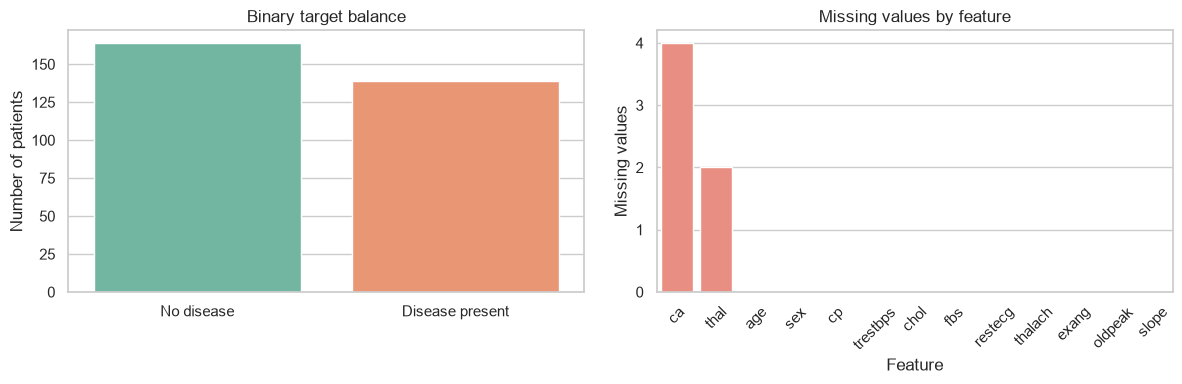

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=eda_data, x='disease_label', hue='disease_label', legend=False, ax=axes[0], palette='Set2')
axes[0].set_title('Binary target balance')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of patients')

missing = X.isna().sum().sort_values(ascending=False)
sns.barplot(x=missing.index, y=missing.values, ax=axes[1], color='salmon')
axes[1].set_title('Missing values by feature')
axes[1].set_xlabel('Feature')
axes[1].set_ylabel('Missing values')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

age              trestbps                  chol          \
                median   mean   std   median    mean    std median    mean   
disease_label                                                                
Disease present   58.0  56.63  7.94    130.0  134.57  18.77  249.0  251.47   
No disease        52.0  52.59  9.51    130.0  129.25  16.20  234.5  242.64   

                       thalach                oldpeak                 ca  \
                   std  median    mean    std  median  mean   std median   
disease_label                                                              
Disease present  49.49   142.0  139.26  22.59     1.4  1.57  1.30    1.0   
No disease       53.46   161.0  158.38  19.20     0.2  0.59  0.78    0.0   

                             
                 mean   std  
disease_label                
Disease present  1.14  1.02  
No disease       0.27  0.63

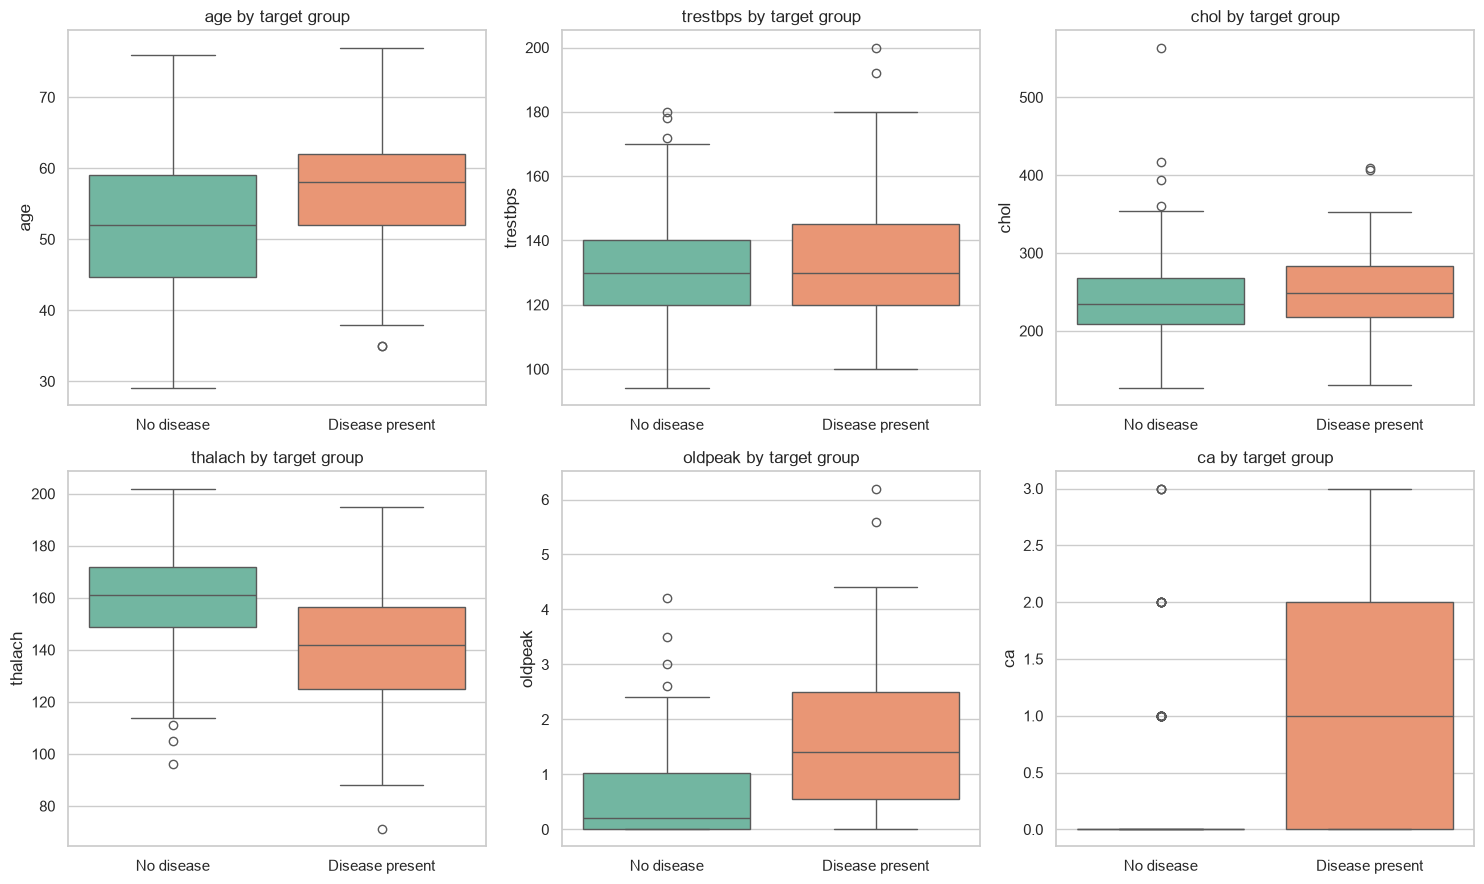

In [6]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

display(eda_data.groupby('disease_label')[numeric_features].agg(['median', 'mean', 'std']).round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for feature, ax in zip(numeric_features, axes.flat):
    sns.boxplot(data=eda_data, x='disease_label', y=feature, hue='disease_label', legend=False, ax=ax, palette='Set2')
    ax.set_title(f'{feature} by target group')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

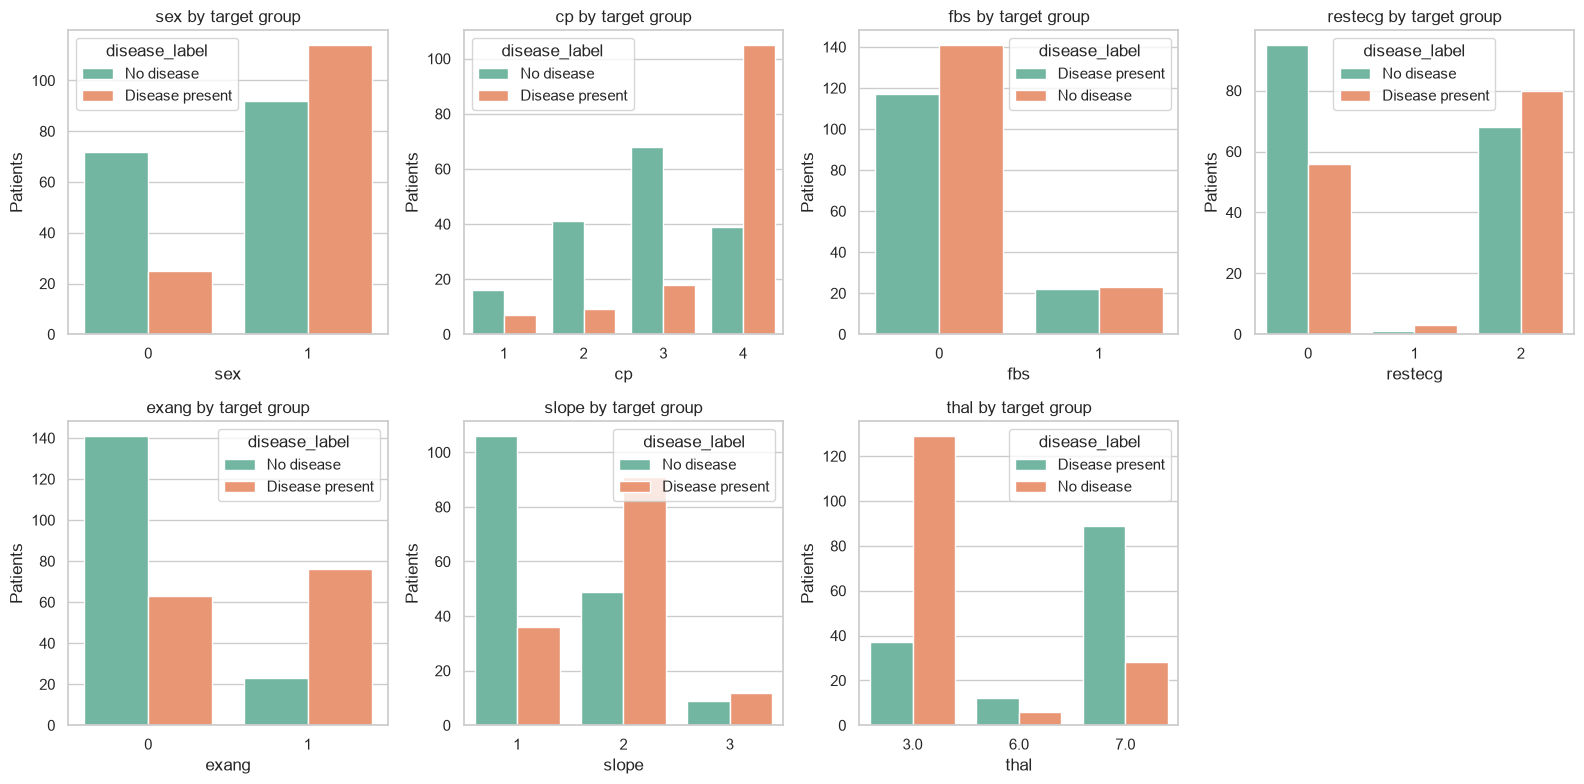

In [7]:
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, ax in zip(categorical_features, axes.flat):
    sns.countplot(data=eda_data, x=feature, hue='disease_label', ax=ax, palette='Set2')
    ax.set_title(f'{feature} by target group')
    ax.set_xlabel(feature)
    ax.set_ylabel('Patients')

# Remove the unused eighth panel.
axes.flat[-1].remove()
plt.tight_layout()
plt.show()

### Observations from this dataset

- The binary comparison is reasonably balanced: 164 patients have `num = 0` (54.1%) and 139 have `num > 0` (45.9%). A stratified split will still be important later, but this is not an extreme imbalance.
- Only `ca` (4 values) and `thal` (2 values) are missing. We should not fill them during EDA; imputation belongs inside a later training pipeline fitted only on training data.
- The disease-present group has a higher median age (58 vs 52), lower median maximum heart rate (142 vs 161), higher median ST depression (`oldpeak`, 1.4 vs 0.2), and a higher median vessel count (`ca`, 1 vs 0). These are associations in this sample, not clinical rules.
- Chest-pain code `4` (asymptomatic) and exercise-induced angina (`exang = 1`) occur more often in the disease-present group. Those patterns make these variables promising candidates for later model comparison.
- Cholesterol and resting blood pressure show overlap between groups. A single feature is unlikely to be sufficient; combining information is the reason to compare multivariable and ensemble models.

## Data preprocessing

Preprocessing makes the data usable by machine-learning algorithms while preserving valid information. It is especially important here because the dataset has two missing-value columns and several categorical variables stored as numbers.

We will later predict **presence of heart disease** as a binary outcome: `0` when `num = 0`, and `1` when `num` is 1–4. This matches the common UCI modelling formulation, but the original five-level target remains available for transparent reporting.

The preprocessing plan is:

- **Numeric measurements** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`): replace missing values with the training-set median, then standardize them. Scaling is important for Logistic Regression; it does not materially affect tree-based models, but using the same transformed inputs makes the comparison consistent.
- **Categorical codes** (`sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal`): replace missing values with the training-set most-frequent category, then one-hot encode them. One-hot encoding prevents a model from interpreting category code `4` as inherently four times code `1`.
- **No preprocessing is fitted now.** The transformer is only defined. In the next stage it will be fitted on the training partition, preventing information from the test set from leaking into the model-development process.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Keep a clean feature matrix. No rows or columns are removed.
X_model = X.copy()

# Create the binary target for the later presence-versus-absence classifiers.
# 0 = no disease; 1 = any recorded disease presence (original num values 1–4).
y_binary = (y['num'] > 0).astype(int)

numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

numeric_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_preprocessor, numeric_features),
        ('categorical', categorical_preprocessor, categorical_features),
    ]
)

print('Binary target counts:')
display(y_binary.value_counts().sort_index().rename({0: 'No disease', 1: 'Disease present'}))
print('\nPreprocessor defined. It will be fitted only after the train-test split.')

Binary target counts:


num
No disease         164
Disease present    139
Name: count, dtype: int64


Preprocessor defined. It will be fitted only after the train-test split.


### Why this design avoids leakage

If we calculated a median, most-frequent category, scaling mean, or category list using all 303 rows before splitting, the held-out test set would influence the transformation. That is data leakage: the model would indirectly learn from data it is supposed not to have seen. Putting these transformations inside `preprocessor` ensures that a later `Pipeline` learns them from training data only.

We use median imputation for the numeric `ca` feature because a median is less sensitive to unusual values than a mean. For `thal`, a categorical test-result code, the most-frequent-category strategy retains every row without inventing a fractional category. These are initial, transparent choices; we can revisit them later if validation shows a reason to do so.

## Train-test split

A test set is a portion of the data held back from model development. It gives us one final, honest check of how well a chosen model might perform on previously unseen records. We will use 80% of records for training and 20% for testing.

`stratify=y_binary` preserves the approximate disease/no-disease proportion in both partitions. `random_state=42` makes this split reproducible: rerunning the notebook produces the same train and test rows.

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_binary,
    test_size=0.20,
    stratify=y_binary,
    random_state=42,
)

print(f'Training features: {X_train.shape}')
print(f'Test features:     {X_test.shape}')

split_summary = (
    pd.DataFrame({
        'Training set': y_train.value_counts(normalize=True).sort_index(),
        'Test set': y_test.value_counts(normalize=True).sort_index(),
    })
    .rename(index={0: 'No disease', 1: 'Disease present'})
    .mul(100)
    .round(1)
)

print('\nClass percentage in each split:')
display(split_summary)

Training features: (242, 13)
Test features:     (61, 13)

Class percentage in each split:


,Training set,Test set
num,,
No disease,54.1,54.1
Disease present,45.9,45.9


### What must happen next

From this point onward, the test set stays untouched during model fitting, preprocessing fitting, hyperparameter selection, and model selection. We will fit the preprocessing-and-model pipeline on `X_train` and `y_train`; predictions on `X_test` will be reserved for final evaluation.

The test set has about 61 records, so its metrics can vary noticeably with a different random split. That is why later model selection will also use cross-validation within the training set rather than treating a single test score as definitive.

## Baseline model: Logistic Regression

A baseline is a sensible, comparatively simple model that later approaches must beat to justify their added complexity. Logistic Regression estimates the probability of the positive class from a weighted combination of the input features. It is not an ensemble, which makes it a useful reference point for this project.

The pipeline combines the previously defined preprocessing with the classifier. During each cross-validation fold, preprocessing is fitted only on that fold's training portion. This preserves the same no-leakage rule used for the train-test split.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

logistic_baseline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

# Stratified folds preserve the target balance within each validation fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
}

baseline_cv_results = cross_validate(
    logistic_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
)

baseline_summary = pd.DataFrame({
    metric: [
        baseline_cv_results[f'test_{metric}'].mean(),
        baseline_cv_results[f'test_{metric}'].std(),
    ]
    for metric in scoring
}, index=['mean', 'standard deviation']).T.round(3)

display(baseline_summary)

,mean,standard deviation
accuracy,0.847,0.022
precision,0.878,0.071
recall,0.784,0.034
f1,0.825,0.015
roc_auc,0.906,0.020


### Reading the baseline metrics

- **Accuracy** is the share of correct predictions, but it can hide whether one class is being missed.
- **Precision** answers: when the model predicts disease, how often is it correct?
- **Recall** answers: among patients with disease in the data, how many did the model identify? In an educational early-detection framing, missed positives make recall particularly important to inspect.
- **F1-score** balances precision and recall.
- **ROC-AUC** measures how well predicted probabilities rank positive cases above negative cases across many decision thresholds.

The mean is the typical cross-validation performance on training data; the standard deviation shows how much the result changes across folds. We should prefer an ensemble only if it gives a meaningful improvement in the metrics that matter, not merely a higher accuracy.

In [11]:
# Fit once on all training data for later comparison and interpretation.
# Do not call predict or predict_proba on X_test at this point.
logistic_baseline.fit(X_train, y_train)
print('Logistic Regression baseline fitted on the training set.')

Logistic Regression baseline fitted on the training set.


## Individual and ensemble model candidates

We will compare four new candidates against Logistic Regression. Each is wrapped in the same preprocessing pipeline so differences in performance are attributable to the learning algorithm rather than inconsistent data handling.

- **Decision Tree:** one tree that learns decision rules. It is easy to visualize but can overfit a small dataset.
- **Random Forest:** many decision trees trained on varied samples and feature subsets; their predictions are averaged to reduce the instability of one tree.
- **AdaBoost:** a sequence of small trees in which later learners focus more on observations earlier learners handled poorly.
- **Soft Voting Classifier:** combines predicted probabilities from Logistic Regression, a Decision Tree, Random Forest, and AdaBoost. Its predicted class reflects the average probability across the component models.
- **XGBoost:** gradient boosting that builds trees sequentially while using regularization and randomized row/feature sampling to control overfitting.
- **LightGBM:** a gradient-boosting implementation designed to train tree ensembles efficiently. Its leaf-wise tree growth can be powerful, but must be validated carefully on a small dataset.

In [16]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Keep model settings modest and reproducible for this small dataset.
decision_tree = DecisionTreeClassifier(random_state=42)
random_forest = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
)
adaboost = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=0.5,
    random_state=42,
)
xgboost = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
)
lightgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=15,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

# A soft vote needs every component to provide class probabilities.
voting_classifier = VotingClassifier(
    estimators=[
        ('logistic_regression', LogisticRegression(max_iter=1000, random_state=42)),
        ('decision_tree', DecisionTreeClassifier(random_state=42)),
        ('random_forest', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
        ('adaboost', AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42)),
    ],
    voting='soft',
)

candidate_models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor),
        ('model', decision_tree),
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', random_forest),
    ]),
    'AdaBoost': Pipeline([
        ('preprocessor', preprocessor),
        ('model', adaboost),
    ]),
    'Soft Voting Classifier': Pipeline([
        ('preprocessor', preprocessor),
        ('model', voting_classifier),
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor),
        ('model', xgboost),
    ]),
    'LightGBM': Pipeline([
        ('preprocessor', preprocessor),
        ('model', lightgbm),
    ]),
}

print('Candidate models:')
for name, pipeline in candidate_models.items():
    print(f"- {name}: {pipeline.named_steps['model'].__class__.__name__}")

Candidate models:
- Logistic Regression: LogisticRegression
- Decision Tree: DecisionTreeClassifier
- Random Forest: RandomForestClassifier
- AdaBoost: AdaBoostClassifier
- Soft Voting Classifier: VotingClassifier
- XGBoost: XGBClassifier
- LightGBM: LGBMClassifier


### Fair-comparison rules

All candidates use the same `X_train`, `y_train`, cross-validation strategy, preprocessing logic, and metrics. Their random states are fixed where applicable for reproducibility. We have not tuned hyperparameters yet: these are clear initial configurations, not a claim that any algorithm is optimally configured.

The Voting Classifier is not automatically expected to win. If its members make similar errors, averaging their probabilities may add little value. Its value must be demonstrated by the next comparison rather than assumed from its complexity.

## Model comparison

We now evaluate every candidate with the same stratified five-fold cross-validation on `X_train` and `y_train`. Each fold fits a fresh copy of the complete pipeline, including its imputer, encoder, scaler, and classifier.

This is a development-stage comparison, not a final test result. The test set remains reserved for the selected model after we have reviewed performance, behaviour, and limitations.

In [17]:
comparison_rows = []
fold_scores = {}

for name, pipeline in candidate_models.items():
    results = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
    )
    fold_scores[name] = results

    row = {'Model': name}
    for metric in scoring:
        scores = results[f'test_{metric}']
        row[metric] = scores.mean()
        row[f'{metric}_std'] = scores.std()
    comparison_rows.append(row)

comparison_results = (
    pd.DataFrame(comparison_rows)
    .set_index('Model')
    .sort_values('roc_auc', ascending=False)
)

metric_columns = list(scoring.keys())
display(comparison_results[metric_columns].round(3))

print('Cross-validation standard deviations:')
display(comparison_results[[f'{metric}_std' for metric in metric_columns]].round(3))

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.847,0.878,0.784,0.825,0.906
Random Forest,0.810,0.813,0.765,0.785,0.890
AdaBoost,0.822,0.817,0.792,0.803,0.883
Soft Voting Classifier,0.765,0.764,0.711,0.734,0.874
XGBoost,0.793,0.785,0.765,0.772,0.858
LightGBM,0.777,0.755,0.765,0.758,0.853
Decision Tree,0.702,0.684,0.675,0.675,0.700


Cross-validation standard deviations:


,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
Model,,,,,
Logistic Regression,0.022,0.071,0.034,0.015,0.020
Random Forest,0.029,0.044,0.074,0.039,0.037
AdaBoost,0.049,0.070,0.062,0.057,0.029
Soft Voting Classifier,0.015,0.042,0.048,0.018,0.019
XGBoost,0.044,0.063,0.068,0.046,0.029
LightGBM,0.032,0.048,0.055,0.035,0.028
Decision Tree,0.047,0.069,0.069,0.044,0.044


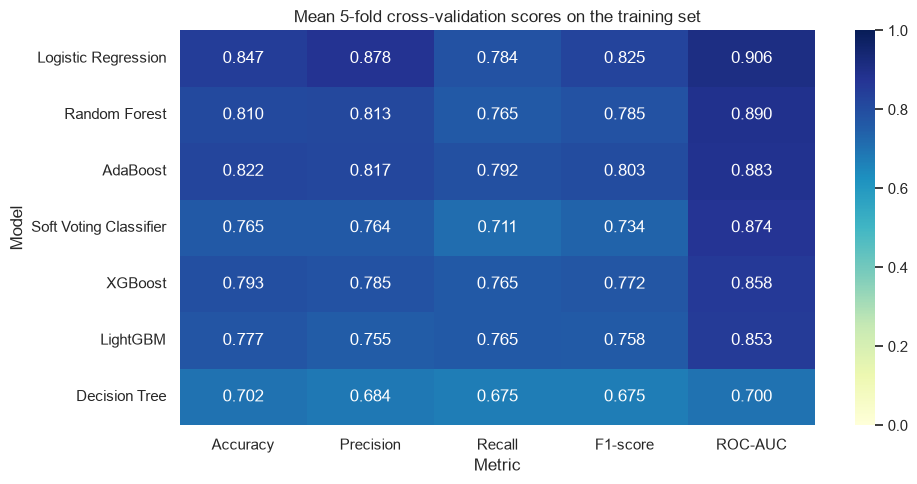

In [18]:
plot_data = comparison_results[metric_columns].rename(columns={
    'accuracy': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1': 'F1-score',
    'roc_auc': 'ROC-AUC',
})

plt.figure(figsize=(10, 5))
sns.heatmap(plot_data, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Mean 5-fold cross-validation scores on the training set')
plt.xlabel('Metric')
plt.ylabel('Model')
plt.tight_layout()
plt.show()

### How to make a meaningful comparison

- Start with **recall** and **ROC-AUC**, not accuracy alone. A classifier that misses many disease-present records is not automatically acceptable just because its accuracy is high.
- Look for a trade-off: a model can raise recall by predicting disease more often, which may lower precision. F1-score helps summarize that balance.
- Compare the means with their standard deviations. A small difference smaller than fold-to-fold variation is weak evidence of a real improvement.
- Compare every ensemble with the Logistic Regression and Decision Tree references. An ensemble should earn its added complexity through a meaningful, stable benefit.

Do not choose a final model solely from the highest cell in the heatmap. The next review will examine model behaviour and then choose a candidate before its single final evaluation on `X_test`.

## Model interpretation

Performance scores answer *how well* a model performed; interpretation helps us understand *what patterns it used*. Here we inspect feature contributions for models that expose them and examine the cross-validated errors of the provisional ROC-AUC leader.

Feature importance is not causality. A feature can appear important because it is correlated with a clinically meaningful variable, because of characteristics of this small dataset, or because the model happened to use it.

In [19]:
from sklearn.base import clone

def feature_contributions(fitted_pipeline):
    """Return comparable feature-contribution magnitudes for supported classifiers."""
    feature_names = fitted_pipeline.named_steps['preprocessor'].get_feature_names_out()
    fitted_model = fitted_pipeline.named_steps['model']

    if hasattr(fitted_model, 'feature_importances_'):
        values = fitted_model.feature_importances_
        label = 'feature importance'
    elif hasattr(fitted_model, 'coef_'):
        values = abs(fitted_model.coef_.ravel())
        label = 'absolute coefficient'
    else:
        raise ValueError('This classifier does not expose native feature contributions.')

    return (
        pd.DataFrame({'feature': feature_names, label: values})
        .sort_values(label, ascending=False)
        .reset_index(drop=True), label
    )

# Soft voting has no single native importance vector, so inspect its component-style alternatives.
interpretable_names = [
    name for name in comparison_results.index
    if name != 'Soft Voting Classifier'
]

fitted_interpretable_models = {}
for name in interpretable_names:
    fitted_pipeline = clone(candidate_models[name]).fit(X_train, y_train)
    fitted_interpretable_models[name] = fitted_pipeline

    contributions, contribution_label = feature_contributions(fitted_pipeline)
    print(f'\n{name}: top 10 features by {contribution_label}')
    display(contributions.head(10))


Logistic Regression: top 10 features by absolute coefficient


,feature,absolute coefficient
0,numeric__ca,1.125993
1,categorical__cp_4.0,0.968677
2,categorical__thal_7.0,0.801445
3,categorical__sex_0.0,0.722601
4,categorical__sex_1.0,0.721391
5,categorical__cp_1.0,0.649175
6,categorical__slope_2.0,0.609170
7,categorical__thal_3.0,0.561458
8,categorical__slope_1.0,0.489227
9,categorical__cp_3.0,0.478354



Random Forest: top 10 features by feature importance


,feature,feature importance
0,numeric__thalach,0.099856
1,categorical__thal_3.0,0.092405
2,numeric__ca,0.092159
3,categorical__cp_4.0,0.086047
4,numeric__oldpeak,0.082165
5,categorical__thal_7.0,0.078872
6,numeric__age,0.075934
7,numeric__chol,0.073161
8,numeric__trestbps,0.066837
9,categorical__exang_0.0,0.032773



AdaBoost: top 10 features by feature importance


,feature,feature importance
0,numeric__thalach,0.151746
1,numeric__chol,0.132016
2,numeric__ca,0.118320
3,numeric__trestbps,0.097909
4,numeric__oldpeak,0.096754
5,numeric__age,0.079979
6,categorical__cp_4.0,0.073392
7,categorical__thal_3.0,0.066379
8,categorical__sex_0.0,0.060367
9,categorical__exang_1.0,0.027405


... (2 outputs left out)


LightGBM: top 10 features by feature importance


,feature,feature importance
0,numeric__age,429
1,numeric__chol,428
2,numeric__thalach,350
3,numeric__oldpeak,281
4,numeric__trestbps,244
5,numeric__ca,162
6,categorical__cp_4.0,101
7,categorical__thal_7.0,97
8,categorical__restecg_0.0,86
9,categorical__slope_2.0,85



Decision Tree: top 10 features by feature importance


,feature,feature importance
0,categorical__thal_3.0,0.292921
1,categorical__cp_4.0,0.119427
2,numeric__ca,0.112877
3,numeric__age,0.092324
4,numeric__oldpeak,0.087132
5,numeric__chol,0.078989
6,numeric__thalach,0.062062
7,categorical__sex_1.0,0.033909
8,numeric__trestbps,0.026549
9,categorical__slope_2.0,0.016138


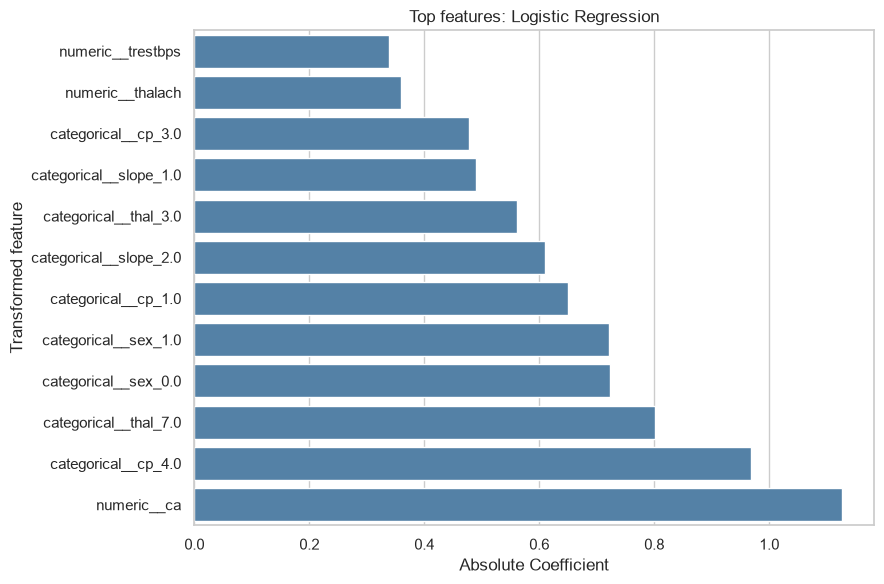

In [20]:
# Plot the leading non-voting model's feature contributions for a focused interpretation.
best_interpretable_name = next(
    name for name in comparison_results.index
    if name != 'Soft Voting Classifier'
)
best_contributions, contribution_label = feature_contributions(
    fitted_interpretable_models[best_interpretable_name]
)
top_features = best_contributions.head(12).sort_values(contribution_label)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x=contribution_label, y='feature', color='steelblue')
plt.title(f'Top features: {best_interpretable_name}')
plt.xlabel(contribution_label.title())
plt.ylabel('Transformed feature')
plt.tight_layout()
plt.show()

Out-of-fold classification report: Logistic Regression
                 precision    recall  f1-score   support

     No disease       0.83      0.90      0.86       131
Disease present       0.87      0.78      0.82       111

       accuracy                           0.85       242
      macro avg       0.85      0.84      0.84       242
   weighted avg       0.85      0.85      0.85       242



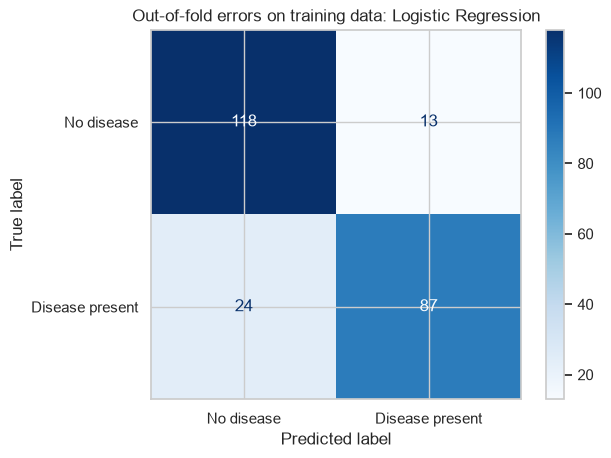

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict

# These are out-of-fold predictions on training data: each row is predicted by a model that did not fit that row.
provisional_name = comparison_results['roc_auc'].idxmax()
provisional_pipeline = clone(candidate_models[provisional_name])
y_train_oof_pred = cross_val_predict(
    provisional_pipeline, X_train, y_train, cv=cv, method='predict'
)

print(f'Out-of-fold classification report: {provisional_name}')
print(classification_report(y_train, y_train_oof_pred, target_names=['No disease', 'Disease present']))

ConfusionMatrixDisplay(
    confusion_matrix(y_train, y_train_oof_pred),
    display_labels=['No disease', 'Disease present'],
).plot(cmap='Blues')
plt.title(f'Out-of-fold errors on training data: {provisional_name}')
plt.show()

### How to interpret these outputs

- For tree and boosting models, a higher feature-importance value means the feature was more useful for the model's splits. For Logistic Regression, the displayed value is the absolute coefficient after preprocessing; it shows influence magnitude but not direction.
- One-hot encoded names such as `categorical__cp_4` refer to one specific category. Interpret them using the feature guide, rather than treating the numeric code itself as a scale.
- In the confusion matrix, the lower-left cell contains false negatives: disease-present records predicted as no disease. The upper-right cell contains false positives. Whether one is more costly is a domain decision, so we will explicitly weigh this before selecting the final model.
- These are training-set cross-validation diagnostics. They are useful for understanding candidate behaviour, but are not a replacement for the untouched final test set.

## Final model selection

The final model is selected using the cross-validation results on the training data, before looking at `X_test`. For this run, **Logistic Regression** is selected. It has the highest ROC-AUC (0.906), accuracy (0.847), precision (0.878), F1-score (0.825), and the second-highest recall (0.784). Its ROC-AUC and F1 variation across folds are also lower than the tree and boosting alternatives.

AdaBoost has marginally higher recall (0.792 versus 0.784), but its ROC-AUC, precision, F1-score, and fold-to-fold stability are weaker. Random Forest is the nearest overall ensemble candidate (ROC-AUC 0.890), but its 0.016 ROC-AUC difference is not a meaningful enough gain over Logistic Regression—in fact it is lower. Added ensemble complexity is therefore not justified for this dataset and configuration.

This selection is evidence-based for this project data and split; it is not a general claim that Logistic Regression is always better than ensemble models.

In [22]:
selected_model_name = 'Logistic Regression'
selected_model = clone(candidate_models[selected_model_name])

selection_evidence = comparison_results.loc[
    ['Logistic Regression', 'Random Forest', 'AdaBoost'],
    ['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
].round(3)

print(f'Selected model: {selected_model_name}')
print('\nEvidence against the strongest ensemble alternatives:')
display(selection_evidence)

# This pipeline is intentionally not fitted or evaluated on X_test here.
# The next stage will fit it on X_train/y_train, save it, and evaluate the final artifact once on X_test.

Selected model: Logistic Regression

Evidence against the strongest ensemble alternatives:


,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.847,0.878,0.784,0.825,0.906
Random Forest,0.810,0.813,0.765,0.785,0.890
AdaBoost,0.822,0.817,0.792,0.803,0.883


### Selection criteria used

1. Strong discrimination: prioritize ROC-AUC because it evaluates probability ranking across thresholds.
2. Balanced error behaviour: inspect precision, recall, and F1-score together.
3. Stability: prefer results with lower variation across validation folds when mean scores are close.
4. Parsimony: prefer the simpler model when a more complex alternative does not deliver a meaningful, reliable benefit.

The test set remains untouched until the final saved pipeline is evaluated.

## Model saving and exported artifacts

The selected Logistic Regression pipeline is now fitted on `X_train` and `y_train`, then evaluated once on the untouched `X_test` and `y_test`. The saved Joblib file contains both preprocessing and classification, which is essential for consistent future predictions.

Final held-out test performance: accuracy **0.8689**, precision **0.8125**, recall **0.9286**, F1-score **0.8667**, and ROC-AUC **0.9578**. These values are a single test-set estimate, not a guarantee of clinical performance.

In [23]:
from pathlib import Path
import subprocess
import sys

# Works whether the notebook is run with the repository root or notebooks/ as its working directory.
project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent

subprocess.run(
    [sys.executable, str(project_root / 'src' / 'models' / 'train_final_model.py')],
    check=True,
)

CompletedProcess(args=['c:\\Python314\\python.exe', 'D:\\Programming files\\GitHub\\ML-Project\\src\\models\\train_final_model.py'], returncode=0)

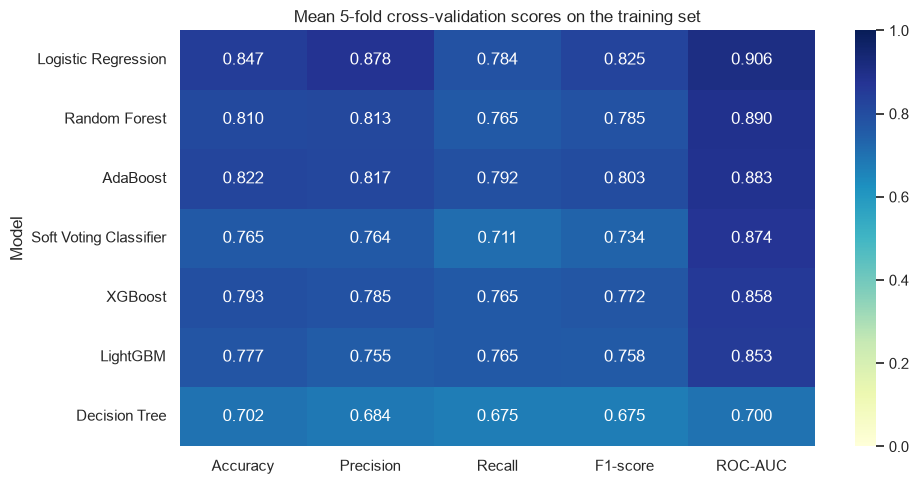

Saved cross-validation comparison table and figure to reports/.


In [24]:
# Save the actual cross-validation comparison produced earlier in this notebook.
report_dir = project_root / 'reports'
report_dir.mkdir(exist_ok=True)
comparison_results.round(4).to_csv(report_dir / 'cross_validation_model_comparison.csv')

comparison_plot = comparison_results[metric_columns].rename(columns={
    'accuracy': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1': 'F1-score',
    'roc_auc': 'ROC-AUC',
})
plt.figure(figsize=(10, 5))
sns.heatmap(comparison_plot, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Mean 5-fold cross-validation scores on the training set')
plt.tight_layout()
plt.savefig(report_dir / 'cross_validation_model_comparison.png', dpi=200)
plt.show()

print('Saved cross-validation comparison table and figure to reports/.')

### Saved files

- `data/raw/heart_disease_original.csv`: imported UCI features with the original five-level `num` target.
- `data/processed/train.csv` and `data/processed/test.csv`: reproducible split with the binary modelling target.
- `models/heart_disease_logistic_pipeline.joblib`: the complete fitted preprocessing-and-prediction pipeline.
- `models/heart_disease_logistic_metadata.json`: target definition, split details, and final test metrics.
- `reports/`: final test metrics, predictions, classification report, cross-validation comparison, and PNG figures.

The next project stage is the Streamlit demonstration, which will load this Joblib pipeline rather than duplicate training or preprocessing logic.

## Streamlit demonstration

The Streamlit application is implemented in `app/app.py`. It imports the saved `heart_disease_logistic_pipeline.joblib` file, so the application uses exactly the same imputing, encoding, scaling, and Logistic Regression logic as the evaluated final model.

Start it from the repository root with:

```powershell
streamlit run app/app.py
```

The interface translates readable clinical options into the UCI numeric codes expected by the pipeline. It shows the predicted probability and class, and includes an educational-use warning. It must not be interpreted as a medical diagnosis.